# Student Engagement Detection from Webcam Frames

**Machine Learning Pipeline summative · Joshua Agonzibwa**

My Introduction to Machine Learning summative built an early-warning model for at-risk students from *tabular* data (the OULAD click-stream). Its main finding was that **behaviour matters far more than background**: how much a student engages predicts failure and withdrawal better than who the student is.

This project takes the same use case into **non-tabular data**. Instead of counting clicks, it reads engagement directly from a webcam frame of a student in an online class and classifies it into six states:

| Engaged | Not engaged |
|---|---|
| `engaged`, `confused`, `frustrated` | `bored`, `drowsy`, `looking_away` |

A confused or frustrated student is still attending to the lesson, so the dataset counts those states as engaged.

**Notebook contents**

1. Setup
2. Data acquisition
3. Data exploration and feature interpretation
4. Preprocessing
5. Model 1: a baseline CNN trained from scratch
6. Model 2: transfer learning with MobileNetV2 and hyperparameter tuning
7. Final training (two-phase fine-tuning)
8. Evaluation on the held-out test set
9. Error analysis
10. Saving the model
11. Prediction function
12. Retraining function
13. Conclusions and limitations

The reusable code lives in `src/` (`preprocessing.py`, `model.py`, `prediction.py`, `retrain.py`) so the notebook, the API and the retraining job all run exactly the same functions.

## 1. Setup

In [1]:
import os, sys, json, time, random, warnings
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import tensorflow as tf
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support, roc_auc_score, roc_curve, auc, log_loss)

from src import config, preprocessing, model as model_lib, prediction

SEED = config.SEED
keras.utils.set_random_seed(SEED)
FAST = os.getenv("NB_FAST") == "1"          # quick dry run of every cell

CLASS_NAMES = config.CLASS_NAMES
COLORS = {"engaged": "#1b9e77", "confused": "#3b82c4", "frustrated": "#7b61c9",
          "bored": "#d98b1f", "drowsy": "#c2553d", "looking_away": "#b0447a"}
PALETTE = [COLORS[c] for c in CLASS_NAMES]
FIG_DIR = config.BASE_DIR / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

print("Python     ", sys.version.split()[0])
print("TensorFlow ", tf.__version__)
print("scikit-learn", sklearn.__version__)
print("NumPy      ", np.__version__)
tf.get_logger().setLevel("ERROR")
print("GPU        ", tf.config.list_physical_devices("GPU") or "none (CPU run)")

Python      3.13.14
TensorFlow  2.21.0
scikit-learn 1.9.1
NumPy       2.5.4
GPU         none (CPU run)


## 2. Data acquisition

**Dataset:** [Student-engagement](https://www.kaggle.com/datasets/joyee19/studentengagement) by Joyeeta Dey (Kaggle): 2,120 frames captured by laptop webcams during online classes, labelled with six engagement states.

`preprocessing.acquire()` downloads the 40 MB archive and builds three folders. If they are already populated the download is skipped.

| Folder | Share | Purpose |
|---|---|---|
| `data/train` | about 79% | Training, with a validation part carved out in code |
| `data/test` | 15% | Held-out evaluation; never trained on |
| `data/retrain_pool` | 6% | Held back as *future* data. Not used anywhere in this notebook's training. It is what gets uploaded through the UI to demonstrate retraining |

In [2]:
if sum(preprocessing.class_counts(config.TRAIN_DIR).values()) == 0:
    preprocessing.acquire()          # download + build data/train and data/test
else:
    print("data/train and data/test are already populated; skipping the download.")

counts = pd.DataFrame({"train": preprocessing.class_counts(config.TRAIN_DIR),
                       "test": preprocessing.class_counts(config.TEST_DIR),
                       "retrain_pool": preprocessing.class_counts(config.POOL_DIR)})
counts["total"] = counts.sum(axis=1)
counts["group"] = [config.ENGAGEMENT_GROUP[c] for c in counts.index]
counts.loc["TOTAL"] = [counts.train.sum(), counts.test.sum(), counts.retrain_pool.sum(), counts.total.sum(), ""]
counts

data/train and data/test are already populated; skipping the download.


,train,test,retrain_pool,total,group
bored,270,58,30,358,Not engaged
confused,279,60,30,369,Engaged
drowsy,203,40,20,263,Not engaged
engaged,257,60,30,347,Engaged
frustrated,270,60,30,360,Engaged
looking_away,323,70,30,423,Not engaged
TOTAL,1602,348,170,2120,


### How the test set was made

The images are **consecutive frames cut from videos**, so frame 412 and frame 413 are nearly the same picture. Splitting single frames at random would put near-duplicates on both sides of the split and report an inflated test score.

`preprocessing.build_splits` therefore cuts each class into **blocks of 10 consecutive frames** and assigns whole blocks to the test set (15% of each class) and to the retrain pool (6%). The validation set is carved out of `data/train` the same way (`preprocessing.is_validation_file`, a hash of the block id), so the assignment never changes when new images are added later.

In [3]:
train_paths_all, train_labels_all = preprocessing.list_images(config.TRAIN_DIR)
tr_p, tr_l, va_p, va_l = preprocessing.train_val_split(train_paths_all, train_labels_all)
te_p, te_l = preprocessing.list_images(config.TEST_DIR)

split_table = pd.DataFrame({
    "train": np.bincount(tr_l, minlength=6), "validation": np.bincount(va_l, minlength=6),
    "test": np.bincount(te_l, minlength=6)}, index=CLASS_NAMES)
split_table.loc["TOTAL"] = split_table.sum()
print(f"train={len(tr_p)}  validation={len(va_p)}  test={len(te_p)}")
split_table

train=1378  validation=224  test=348


,train,validation,test
bored,240,30,58
confused,227,52,60
drowsy,188,15,40
engaged,195,62,60
frustrated,241,29,60
looking_away,287,36,70
TOTAL,1378,224,348


## 3. Data exploration and feature interpretation

### 3.1 What the images look like

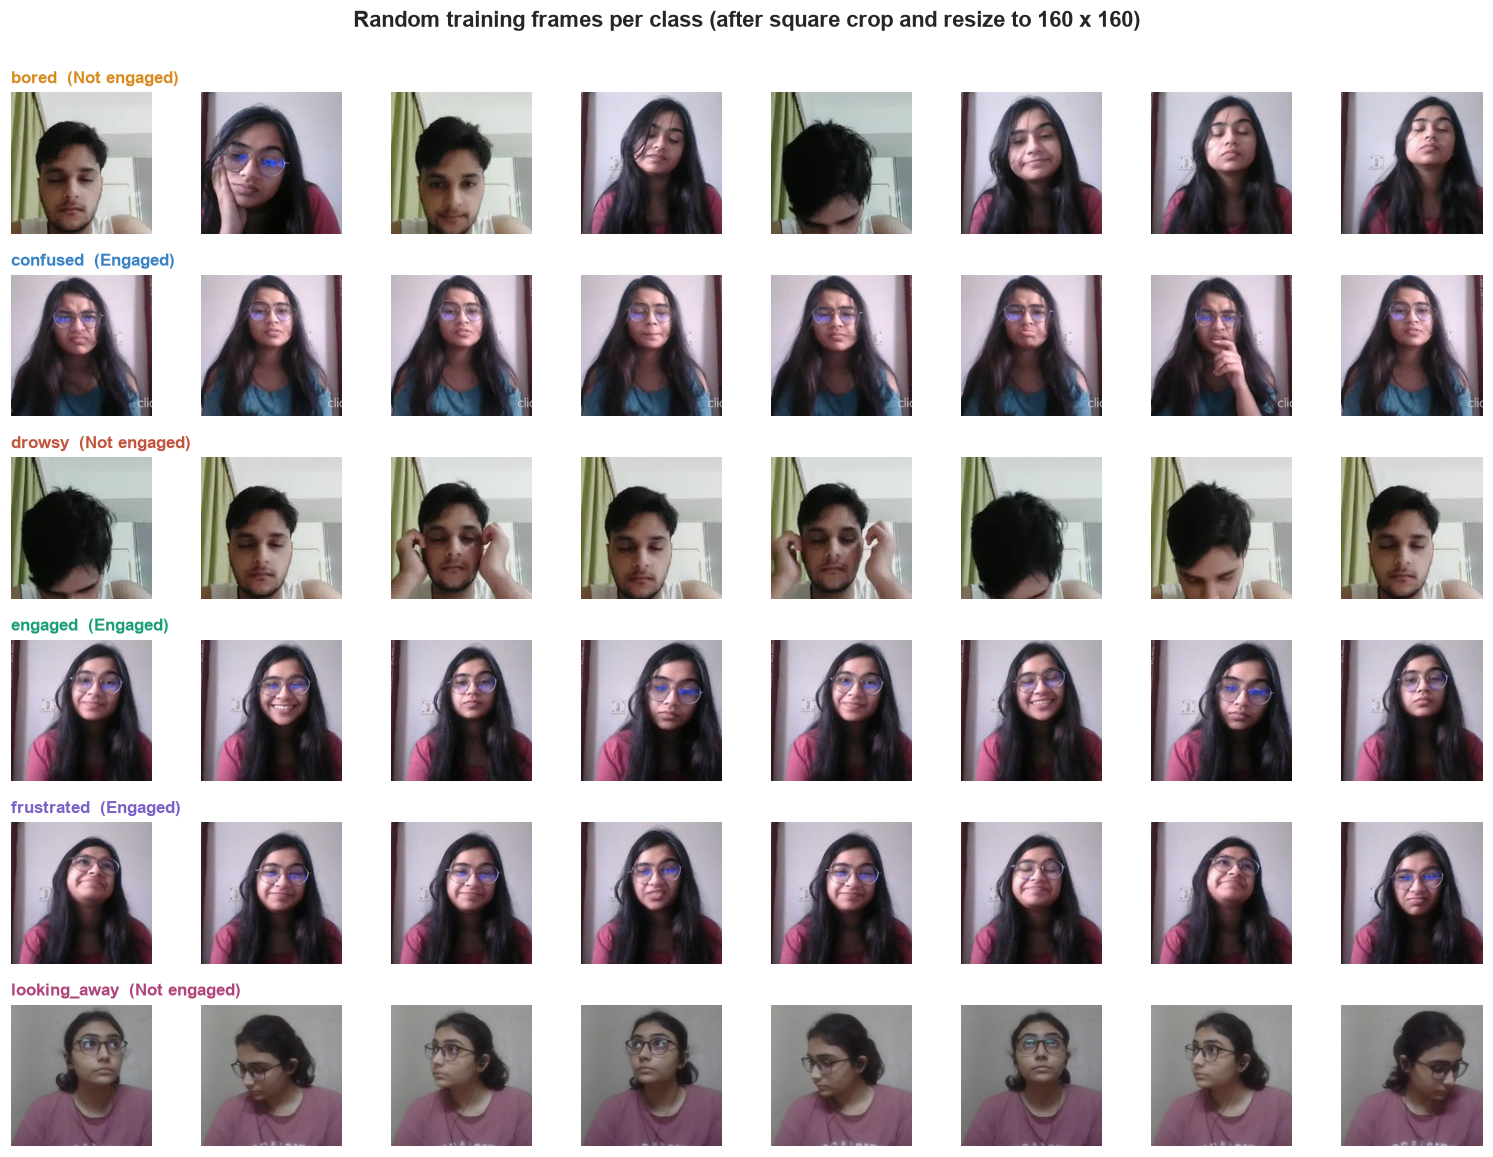

In [4]:
rng = random.Random(SEED)
fig, axes = plt.subplots(6, 8, figsize=(14, 10.5))
for row, name in enumerate(CLASS_NAMES):
    files = sorted((config.TRAIN_DIR / name).glob("*.jpg"))
    for col, f in enumerate(rng.sample(files, 8)):
        axes[row, col].imshow(Image.open(f)); axes[row, col].axis("off")
    axes[row, 0].set_title(f"{name}  ({config.ENGAGEMENT_GROUP[name]})", loc="left", color=COLORS[name], fontsize=11)
plt.suptitle("Random training frames per class (after square crop and resize to 160 x 160)", y=1.0, fontweight="bold")
plt.tight_layout(); plt.show()

**Observation.** The dataset contains only a handful of students, each recorded in their own room. Some classes come from a single recording session (`looking_away` is one student against a grey wall, `confused` is one student in a blue top), while `engaged` and `frustrated` show the same student in the same room and differ only in her expression. This matters a lot for how the results should be read, and section 13 comes back to it.

### 3.2 Feature 1: class balance

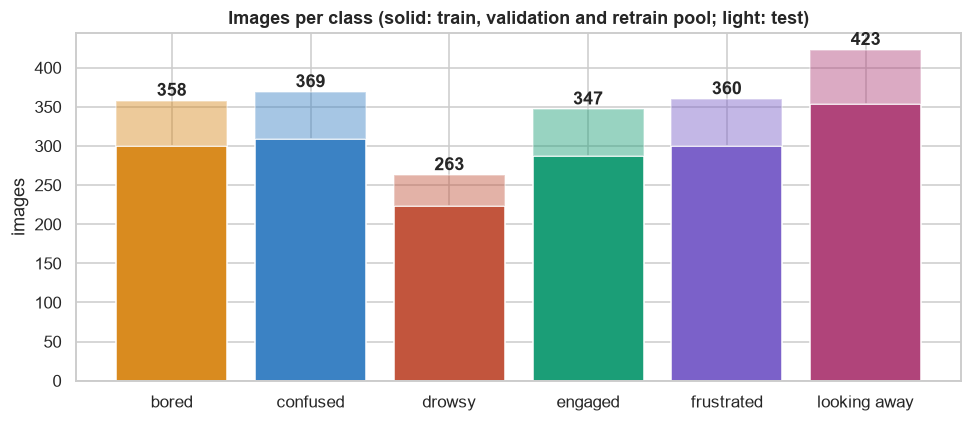

largest / smallest class: 423 / 263 = 1.61
share of 'Engaged' states: 50.8%


In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(6)
rest = counts.loc[CLASS_NAMES, "total"].astype(int) - split_table.loc[CLASS_NAMES, "test"]
ax.bar(x, rest, color=PALETTE, label="train + validation + retrain pool")
ax.bar(x, split_table.loc[CLASS_NAMES, "test"], bottom=rest, color=PALETTE, alpha=0.45, label="test")
for i, c in enumerate(CLASS_NAMES):
    ax.text(i, counts.loc[c, "total"] + 6, int(counts.loc[c, "total"]), ha="center", fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels([c.replace("_", " ") for c in CLASS_NAMES])
ax.set_ylabel("images"); ax.set_title("Images per class (solid: train, validation and retrain pool; light: test)")
plt.tight_layout(); plt.savefig(FIG_DIR / "class_balance.png", dpi=150); plt.show()

totals = counts.loc[CLASS_NAMES, "total"].astype(int)
engaged_share = totals[[c for c in CLASS_NAMES if config.ENGAGEMENT_GROUP[c] == "Engaged"]].sum() / totals.sum()
print(f"largest / smallest class: {totals.max()} / {totals.min()} = {totals.max() / totals.min():.2f}")
print(f"share of 'Engaged' states: {engaged_share:.1%}")

**Interpretation.** The classes are mildly imbalanced: `looking_away` has about 1.6 times as many frames as `drowsy`. That is not severe, but a model could still gain accuracy by neglecting `drowsy`, which is exactly the state a teacher most wants to catch. Two decisions follow: training uses **inverse-frequency class weights**, and evaluation reports **macro-averaged** precision, recall and F1 so every class counts equally. At the two-group level (engaged vs not engaged) the data is almost perfectly balanced.

### 3.3 Features 2 to 5: brightness, contrast, sharpness and colour

Pixels themselves are not interpretable, so `preprocessing.extract_features` computes five measurable properties of each frame.

In [6]:
rows = []
for root, split in ((config.TRAIN_DIR, "train"), (config.TEST_DIR, "test"), (config.POOL_DIR, "retrain_pool")):
    for path, label in zip(*preprocessing.list_images(root)):
        with Image.open(path) as im:
            rows.append({"class": CLASS_NAMES[label], "split": split, **preprocessing.extract_features(im)})
features = pd.DataFrame(rows)
features.groupby("class")[["brightness", "contrast", "sharpness", "warmth", "lower_minus_upper"]].mean().round(1)

,brightness,contrast,sharpness,warmth,lower_minus_upper
class,,,,,
bored,117.6,72.3,10.0,5.9,-63.2
confused,106.5,71.7,9.9,0.9,-82.6
drowsy,136.2,69.5,9.8,14.9,-27.9
engaged,105.1,70.7,9.8,5.2,-74.1
frustrated,104.1,68.8,9.2,5.8,-73.5
looking_away,104.6,35.0,5.1,10.1,-19.1


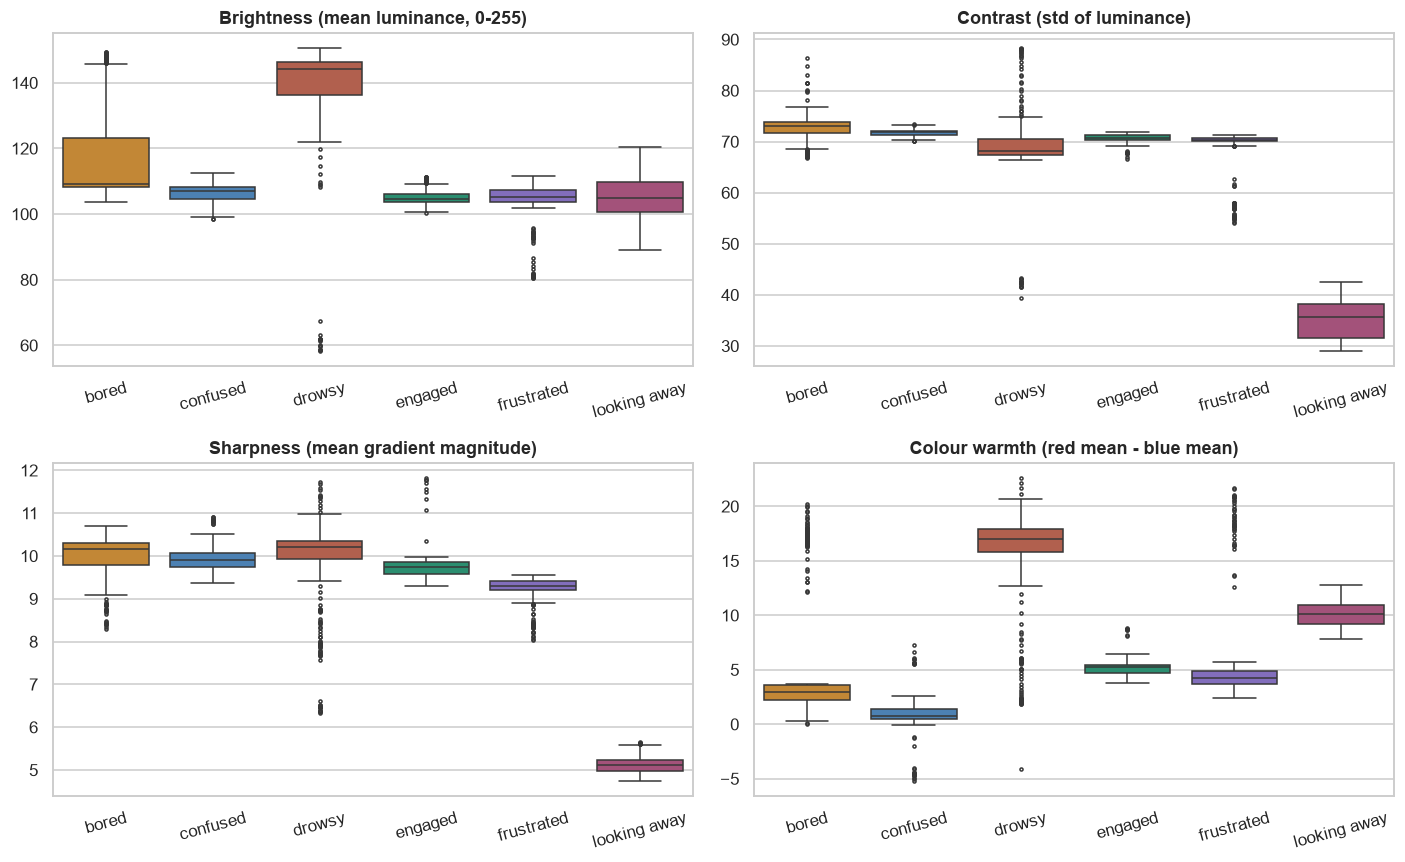

Gap between the highest and lowest class mean, in pooled standard deviations:
  brightness   3.48
  contrast    10.36
  sharpness   10.70
  warmth       4.22


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
titles = {"brightness": "Brightness (mean luminance, 0-255)", "contrast": "Contrast (std of luminance)",
          "sharpness": "Sharpness (mean gradient magnitude)", "warmth": "Colour warmth (red mean - blue mean)"}
for ax, (key, title) in zip(axes.ravel(), titles.items()):
    sns.boxplot(data=features, x="class", y=key, order=CLASS_NAMES, palette=COLORS, hue="class", legend=False,
                ax=ax, fliersize=2, linewidth=1)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xticklabels([c.replace("_", " ") for c in CLASS_NAMES], rotation=15)
plt.tight_layout(); plt.savefig(FIG_DIR / "feature_distributions.png", dpi=150); plt.show()

def separation(key):
    g = features.groupby("class")[key]
    return (g.mean().max() - g.mean().min()) / g.std().mean()
print("Gap between the highest and lowest class mean, in pooled standard deviations:")
for key in titles:
    print(f"  {key:11s} {separation(key):5.2f}")

**Interpretation of the features**

* **Brightness.** `drowsy` frames are clearly brighter than every other class (median about 144 against about 105). Drowsiness does not light up a room: most drowsy clips were recorded by one student in a bright room. `bored` has a wide spread because it mixes two students in two rooms.
* **Contrast and sharpness.** Five classes sit at almost the same level and `looking_away` stands alone far below them (contrast about 35 against about 70, sharpness about 5 against about 10). Those frames were shot with a softer webcam against a plain grey wall. Some of the blur is real signal, because a turning head smears, but most of it is the camera and the background. A classifier could recognise `looking_away` from blur alone.
* **Colour warmth.** Every webcam and wall colour leaves its own colour cast: `drowsy` is the warmest class and `confused` the coolest. `engaged` and `frustrated` have almost identical warmth because they are the same student in the same room.

**The story the data tells.** The dataset has an easy part and a hard part.

* *Easy:* `drowsy`, `looking_away` and `confused` can largely be identified by the recording session (lighting, wall, camera) without looking at the face at all.
* *Hard:* `engaged`, `frustrated` and part of `bored` share a student and a room, so their image statistics are the same and only the facial expression separates them. This is where the model has to do real work.

Three consequences for the pipeline:

1. Augmentation randomises contrast and geometry so the network cannot rely on exact brightness or framing.
2. A pretrained backbone is used, because it already encodes facial structure and can separate the hard classes from few examples.
3. A high test score has to be read as *accuracy on new frames from the same sessions*, not *accuracy on new students*. Retraining on data from new students is how this model becomes useful beyond its dataset, which is why the deployed system has an upload-and-retrain loop.

### 3.4 Average frame per class

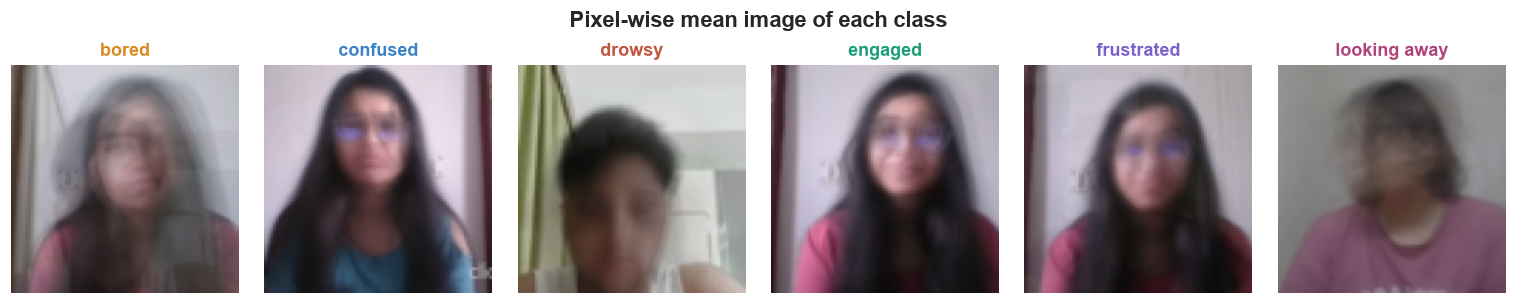

In [8]:
fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
for ax, name in zip(axes, CLASS_NAMES):
    files = sorted((config.TRAIN_DIR / name).glob("*.jpg"))
    mean = np.mean([np.asarray(Image.open(f).resize((80, 80)), dtype=np.float32) for f in files], axis=0)
    ax.imshow(mean.astype(np.uint8)); ax.axis("off"); ax.set_title(name.replace("_", " "), color=COLORS[name])
plt.suptitle("Pixel-wise mean image of each class", fontweight="bold"); plt.tight_layout(); plt.show()

**Interpretation.** Each class averages to a head-and-shoulders silhouette in the centre of the frame, and the background of the dominant recording session shows through, which confirms that some classes come from one or two sessions. A sharper average means a steadier pose; a smeared average means the head moves around or the class mixes several students.

## 4. Preprocessing

Every image, whether it comes from the original archive, from a user's bulk upload or from a single prediction request, goes through the same functions in `src/preprocessing.py`:

| Step | Function | Why |
|---|---|---|
| 1. Validate and decode | `decode_image` | Reject empty, oversized (> 10 MB), corrupt or tiny files before they reach the model |
| 2. Fix orientation | `ImageOps.exif_transpose` | Phone photos store rotation in EXIF metadata |
| 3. Convert to RGB | `image.convert("RGB")` | Drops alpha channels and expands greyscale to 3 channels |
| 4. Square crop | `square_crop` | Frames are 16:9 or 9:16; squashing them would distort faces |
| 5. Resize to 160 x 160 | `resize_image` (Lanczos) | MobileNetV2 input size; small enough for CPU serving |
| 6. Block-wise split | `build_splits`, `train_val_split` | Keeps near-duplicate neighbouring frames on one side of the split |
| 7. Class weights | `compute_class_weights` | Compensates for the mild class imbalance |
| 8. Augmentation | `model.build_augmentation` (inside the model) | Flip, rotation, zoom, translation, contrast; active only in training |
| 9. Scale to [-1, 1] | `Rescaling` layer (inside the model) | What MobileNetV2 expects; being a layer, it cannot be forgotten at serving time |

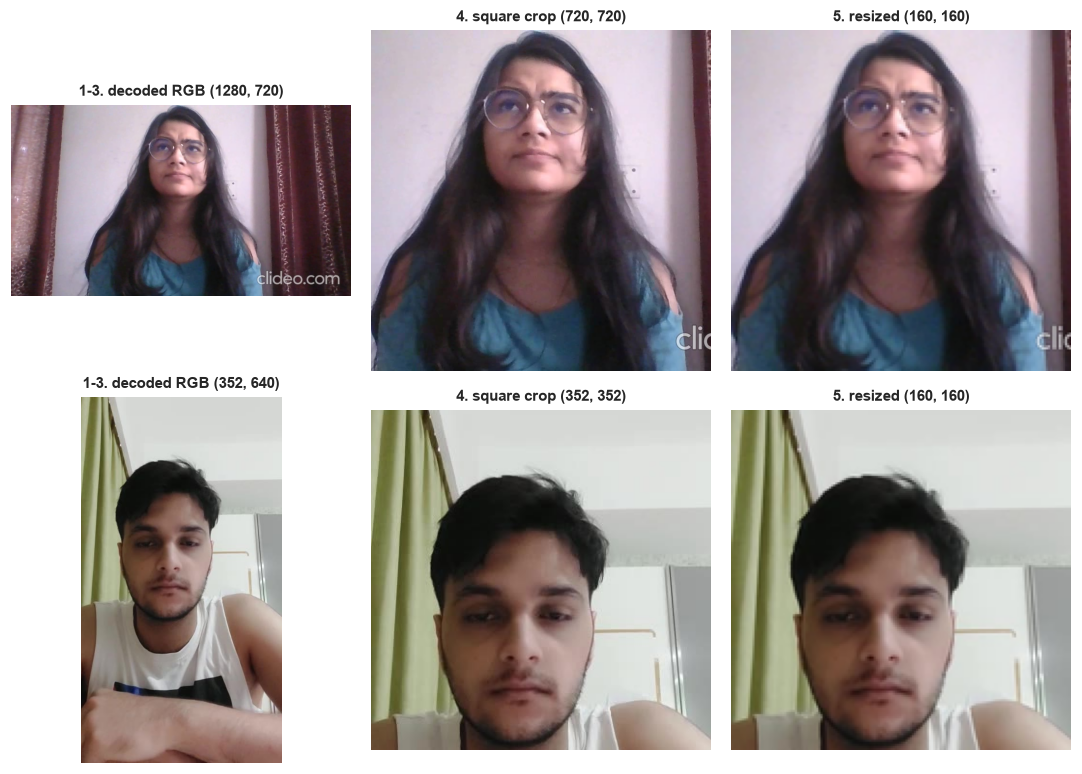

rejected 'empty file': The file is empty.
rejected 'text renamed to .jpg': The file is not a readable image.


In [9]:
# Steps 1-5 on one raw frame from the original archive (if it is on disk).
import zipfile, io
archive = config.RAW_DIR / "studentengagement.zip"
if archive.exists():
    with zipfile.ZipFile(archive) as zf:
        members = [n for n in zf.namelist() if n.lower().endswith(".jpg")]
        landscape = zf.read(members[0])
        portrait = next((zf.read(n) for n in members if "/drowsy/" in n
                         and Image.open(io.BytesIO(zf.read(n))).height > Image.open(io.BytesIO(zf.read(n))).width), None)
    examples = [b for b in (landscape, portrait) if b]
    fig, axes = plt.subplots(len(examples), 3, figsize=(10, 3.6 * len(examples)), squeeze=False)
    for row, raw in enumerate(examples):
        original = preprocessing.decode_image(raw)
        cropped = preprocessing.square_crop(original)
        final = preprocessing.resize_image(original, config.IMG_SIZE)
        for ax, im, title in zip(axes[row], (original, cropped, final),
                                 (f"1-3. decoded RGB {original.size}", f"4. square crop {cropped.size}", f"5. resized {final.size}")):
            ax.imshow(im); ax.set_title(title, fontsize=10); ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Raw archive not on disk (data/raw is git-ignored); showing an already preprocessed image instead.")
    display(Image.open(tr_p[0]))

# Validation rejects bad input instead of crashing:
for bad, why in ((b"", "empty file"), (b"this is not an image", "text renamed to .jpg")):
    try:
        preprocessing.decode_image(bad)
    except preprocessing.InvalidImageError as e:
        print(f"rejected {why!r}: {e}")

In [10]:
# Step 7: class weights
class_weight = preprocessing.compute_class_weights(tr_l)
pd.DataFrame({"train images": np.bincount(tr_l, minlength=6),
              "class weight": [round(class_weight[i], 3) for i in range(6)]}, index=CLASS_NAMES)

,train images,class weight
bored,240,0.957
confused,227,1.012
drowsy,188,1.222
engaged,195,1.178
frustrated,241,0.953
looking_away,287,0.800


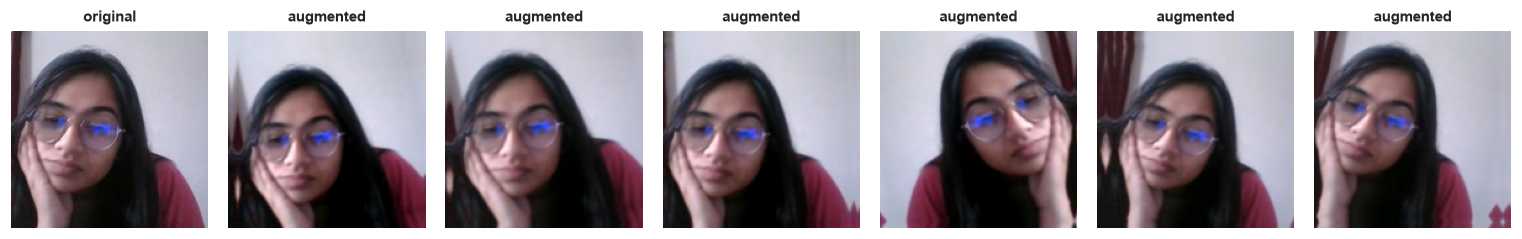

In [11]:
# Step 8: what augmentation does to one training frame
augment = model_lib.build_augmentation()
sample = np.asarray(Image.open(tr_p[5]), dtype=np.float32)[None]
fig, axes = plt.subplots(1, 7, figsize=(14, 2.4))
axes[0].imshow(sample[0].astype(np.uint8)); axes[0].set_title("original", fontsize=10)
for ax in axes[1:]:
    ax.imshow(np.clip(augment(sample, training=True)[0].numpy(), 0, 255).astype(np.uint8)); ax.set_title("augmented", fontsize=10)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

In [12]:
# tf.data input pipelines (decode -> resize -> batch -> prefetch)
BATCH = config.BATCH_SIZE
train_ds = preprocessing.make_dataset(tr_p, tr_l, BATCH, training=True)
val_ds = preprocessing.make_dataset(va_p, va_l, BATCH)
test_ds = preprocessing.make_dataset(te_p, te_l, BATCH)
images, labels = next(iter(train_ds))
print("batch:", images.shape, images.dtype, "| pixel range", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

batch: (32, 160, 160, 3) <dtype: 'float32'> | pixel range 0.0 to 255.0


## 5. Model 1: baseline CNN trained from scratch

A plain convolutional network with no pretrained weights gives a reference point. It uses the same augmentation, Adam, dropout and early stopping, so the comparison with the transfer-learning model isolates the effect of the pretrained backbone.

In [13]:
def build_baseline_cnn():
    inputs = keras.Input(shape=(*config.IMG_SIZE, 3))
    x = model_lib.build_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    for filters in (32, 64, 128):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(CLASS_NAMES), activation="softmax")(x)
    return keras.Model(inputs, outputs, name="baseline_cnn")

keras.utils.set_random_seed(SEED)
baseline = build_baseline_cnn()
baseline.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print(f"baseline parameters: {baseline.count_params():,}")
t0 = time.time()
baseline_history = baseline.fit(train_ds, validation_data=val_ds, epochs=1 if FAST else 10, class_weight=class_weight,
                                callbacks=model_lib.default_callbacks(patience=4), verbose=2)
print(f"trained in {time.time() - t0:.0f}s")

baseline parameters: 94,022
Epoch 1/10


44/44 - 30s - 686ms/step - accuracy: 0.2141 - loss: 1.7676 - val_accuracy: 0.2991 - val_loss: 1.6466 - learning_rate: 0.0010


Epoch 2/10


44/44 - 29s - 649ms/step - accuracy: 0.3585 - loss: 1.5409 - val_accuracy: 0.7321 - val_loss: 1.2138 - learning_rate: 0.0010


Epoch 3/10


44/44 - 28s - 638ms/step - accuracy: 0.5363 - loss: 1.2050 - val_accuracy: 0.7857 - val_loss: 0.9546 - learning_rate: 0.0010


... (13 outputs left out)


Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.


44/44 - 29s - 664ms/step - accuracy: 0.6952 - loss: 0.6988 - val_accuracy: 0.5312 - val_loss: 1.2177 - learning_rate: 0.0010


Restoring model weights from the end of the best epoch: 8.


trained in 306s


## 6. Model 2: transfer learning with MobileNetV2

**Architecture** (`model_lib.build_model`):

```
image (160,160,3) -> augmentation -> rescale to [-1,1]
  -> MobileNetV2 backbone (ImageNet weights, batch-norm frozen)
  -> global average pooling -> dropout -> dense(ReLU, L2) -> dropout -> softmax(6)
```

**Optimisation techniques used**

| Technique | Where |
|---|---|
| Pretrained model | MobileNetV2 trained on ImageNet |
| Regularisation | Dropout (twice), L2 weight decay on the dense layer, data augmentation |
| Optimiser | Adam; learning rate 1e-3 for the head, 1e-4 for fine-tuning |
| Learning-rate schedule | `ReduceLROnPlateau` halves the rate when validation loss stalls |
| Early stopping | Stops when validation loss has not improved for 4 epochs and restores the best weights |
| Class weighting | Inverse-frequency weights in the loss |
| Hyperparameter tuning | Random search over dropout, L2, head width and learning rate (below) |
| Two-phase fine-tuning | Head first, then the top 30 backbone layers at a low learning rate |

### 6.1 Hyperparameter tuning

Running the backbone is the expensive part and it is frozen in phase 1, so its output for every training and validation image is computed **once** and cached. Each hyperparameter trial then trains only the small head on those cached 1,280-dimensional features, which takes seconds instead of minutes.

In [14]:
keras.utils.set_random_seed(SEED)
feature_extractor = keras.Sequential([
    keras.Input(shape=(*config.IMG_SIZE, 3)),
    layers.Rescaling(1.0 / 127.5, offset=-1.0),
    keras.applications.MobileNetV2(input_shape=(*config.IMG_SIZE, 3), include_top=False, weights="imagenet"),
    layers.GlobalAveragePooling2D(),
])
feature_extractor.trainable = False

t0 = time.time()
X_tr = feature_extractor.predict(preprocessing.make_dataset(tr_p, tr_l, 64), verbose=0)
X_va = feature_extractor.predict(val_ds, verbose=0)
y_tr, y_va = np.array(tr_l), np.array(va_l)
print(f"cached features: train {X_tr.shape}, validation {X_va.shape} in {time.time() - t0:.0f}s")

cached features: train (1378, 1280), validation (224, 1280) in 19s


In [15]:
def train_head(dropout, l2, units, lr, epochs=40, seed=SEED):
    keras.utils.set_random_seed(seed)
    head = keras.Sequential([
        keras.Input(shape=(X_tr.shape[1],)),
        layers.Dropout(dropout),
        layers.Dense(units, activation="relu", kernel_regularizer=keras.regularizers.l2(l2)),
        layers.Dropout(dropout),
        layers.Dense(len(CLASS_NAMES), activation="softmax"),
    ])
    head.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = head.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=epochs, batch_size=32, class_weight=class_weight,
                 callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)], verbose=0)
    best = int(np.argmin(h.history["val_loss"]))
    return {"val_loss": h.history["val_loss"][best], "val_accuracy": h.history["val_accuracy"][best], "epochs_run": len(h.history["loss"])}

search_space = {"dropout": [0.2, 0.3, 0.5], "l2": [0.0, 1e-4, 1e-3], "units": [64, 128, 256], "lr": [3e-4, 1e-3, 3e-3]}
rng = random.Random(SEED)
trials = [{"dropout": 0.0, "l2": 0.0, "units": 128, "lr": 1e-3}]           # un-regularised reference
while len(trials) < (3 if FAST else 13):
    candidate = {k: rng.choice(v) for k, v in search_space.items()}
    if candidate not in trials:
        trials.append(candidate)

results = []
for i, params in enumerate(trials):
    out = train_head(**params, epochs=3 if FAST else 40)
    results.append({**params, **out})
    print(f"trial {i:2d}  {params}  val_loss={out['val_loss']:.4f}  val_acc={out['val_accuracy']:.4f}")

tuning = pd.DataFrame(results).sort_values("val_loss").reset_index(drop=True)
regularised = tuning[tuning["dropout"] > 0]             # see the note below the table
best_params = regularised.iloc[0][["dropout", "l2", "units", "lr"]].to_dict()
best_params["units"] = int(best_params["units"])
print("\nBest regularised configuration (lowest validation loss):", best_params)
tuning.style.format({"l2": "{:.0e}", "lr": "{:.0e}", "val_loss": "{:.4f}", "val_accuracy": "{:.4f}"})

trial  0  {'dropout': 0.0, 'l2': 0.0, 'units': 128, 'lr': 0.001}  val_loss=0.0133  val_acc=1.0000


trial  1  {'dropout': 0.5, 'l2': 0.0, 'units': 64, 'lr': 0.003}  val_loss=0.0356  val_acc=0.9955


trial  2  {'dropout': 0.3, 'l2': 0.0, 'units': 64, 'lr': 0.0003}  val_loss=0.0302  val_acc=0.9955


trial  3  {'dropout': 0.5, 'l2': 0.0, 'units': 256, 'lr': 0.003}  val_loss=0.0443  val_acc=0.9821


trial  4  {'dropout': 0.5, 'l2': 0.0, 'units': 256, 'lr': 0.001}  val_loss=0.0294  val_acc=0.9866


trial  5  {'dropout': 0.2, 'l2': 0.0, 'units': 64, 'lr': 0.0003}  val_loss=0.0167  val_acc=0.9911


... (4 outputs left out)

trial 10  {'dropout': 0.3, 'l2': 0.0, 'units': 64, 'lr': 0.001}  val_loss=0.0332  val_acc=0.9911


trial 11  {'dropout': 0.2, 'l2': 0.0, 'units': 128, 'lr': 0.0003}  val_loss=0.0249  val_acc=0.9911


trial 12  {'dropout': 0.3, 'l2': 0.0001, 'units': 256, 'lr': 0.001}  val_loss=0.0678  val_acc=1.0000

Best regularised configuration (lowest validation loss): {'dropout': 0.2, 'l2': 0.0, 'units': 64, 'lr': 0.0003}


,dropout,l2,units,lr,val_loss,val_accuracy,epochs_run
0,0.000000,0e+00,128,1e-03,0.0133,1.0000,13
1,0.200000,0e+00,64,3e-04,0.0167,0.9911,36
2,0.200000,0e+00,128,3e-04,0.0249,0.9911,23
3,0.500000,0e+00,256,1e-03,0.0294,0.9866,24
4,0.300000,0e+00,64,3e-04,0.0302,0.9955,18
5,0.300000,0e+00,64,1e-03,0.0332,0.9911,11
6,0.500000,0e+00,64,3e-03,0.0356,0.9955,12
7,0.500000,0e+00,256,3e-03,0.0443,0.9821,10
8,0.200000,1e-03,128,1e-03,0.0573,1.0000,35
9,0.300000,1e-04,256,1e-03,0.0678,1.0000,10


The table is sorted by validation loss. Every configuration reaches a very high validation accuracy, which is the session effect from section 3 at work: validation frames come from the same recordings as training frames, so frozen ImageNet features already separate them.

The row with dropout 0 and L2 0 is an un-regularised reference. It scores best here and is still **not eligible** to be chosen, for a specific reason: a validation set drawn from the same sessions cannot reward robustness to new students or rooms, so it favours memorising these sessions. The final model therefore uses the best configuration **that has dropout** (dropout 0.2, 64 units, learning rate 3e-4), and regularisation is treated as a design requirement, not something to tune away.

One caveat: the search runs on features of *un-augmented* images, so it is a cheap first filter for the head, not a faithful preview of end-to-end training. Section 7 shows where that matters.

## 7. Final training (two-phase fine-tuning)

`model_lib.train_model` now trains the full model end to end, with augmentation switched on:

* **Phase 1:** backbone frozen, train the head (learning rate from the search).
* **Phase 2:** unfreeze the top 30 backbone layers and continue at learning rate 1e-4. Batch-normalisation layers stay frozen so their ImageNet statistics are not destroyed by small batches.

In [16]:
t0 = time.time()
model, history = model_lib.train_model(
    tr_p, tr_l, va_p, va_l,
    head_epochs=1 if FAST else config.HEAD_EPOCHS,
    fine_tune_epochs=1 if FAST else config.FINE_TUNE_EPOCHS,
    dropout=float(best_params["dropout"]), l2=float(best_params["l2"]),
    dense_units=best_params["units"], head_lr=float(best_params["lr"]),
)
train_seconds = time.time() - t0
print(f"\ntrained in {train_seconds / 60:.1f} min; phase 1 ran {history['phase1_epochs']} epochs, "
      f"phase 2 ran {len(history['loss']) - history['phase1_epochs']} epochs")

Epoch 1/12


44/44 - 42s - 964ms/step - accuracy: 0.5849 - loss: 1.0808 - val_accuracy: 0.8527 - val_loss: 0.6170 - learning_rate: 3.0000e-04


Epoch 2/12


44/44 - 21s - 485ms/step - accuracy: 0.7808 - loss: 0.6045 - val_accuracy: 0.7232 - val_loss: 0.4801 - learning_rate: 3.0000e-04


Epoch 3/12


44/44 - 22s - 501ms/step - accuracy: 0.8512 - loss: 0.4294 - val_accuracy: 0.6964 - val_loss: 0.6008 - learning_rate: 3.0000e-04


... (41 outputs left out)


Epoch 10: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.


44/44 - 20s - 466ms/step - accuracy: 0.9702 - loss: 0.0821 - val_accuracy: 0.9911 - val_loss: 0.0382 - learning_rate: 5.0000e-05


Restoring model weights from the end of the best epoch: 8.



trained in 8.4 min; phase 1 ran 12 epochs, phase 2 ran 10 epochs


In [17]:
model.summary(show_trainable=True)

Model: "engagement_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ image (InputLayer)          │ (None, 160, 160, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 160, 160, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ scale_to_minus1_1           │ (None, 160, 160, 3)   │          0 │   -   │
│ (Rescaling)                 │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenetv2_1.00_160        │ (None, 5, 5, 1280)    │  2,257,984 │   Y   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ avg_pool                    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_1 (Dropout)         │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 64)            │     81,984 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_2 (Dropout)         │ (None, 64)            │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ predictions (Dense)         │ (None, 6)             │        390 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 5,526,548 (21.08 MB)

 Trainable params: 1,593,094 (6.08 MB)

 Non-trainable params: 747,264 (2.85 MB)

 Optimizer params: 3,186,190 (12.15 MB)

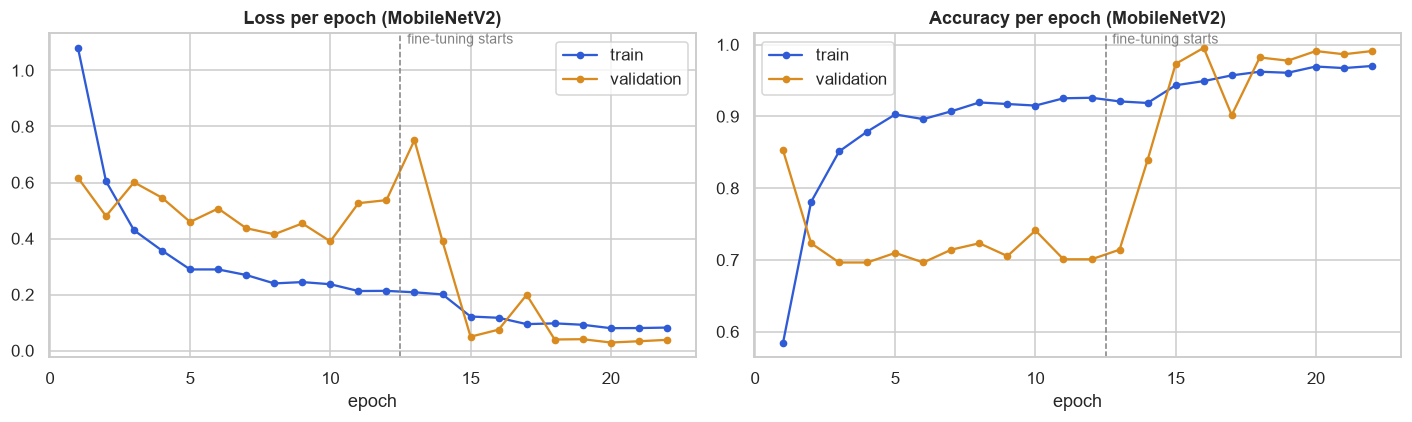

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
epochs_axis = np.arange(1, len(history["loss"]) + 1)
for ax, key, title in ((axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")):
    ax.plot(epochs_axis, history[key], marker="o", ms=4, label="train", color="#2f5bd7")
    ax.plot(epochs_axis, history["val_" + key], marker="o", ms=4, label="validation", color="#d98b1f")
    if len(epochs_axis) > history["phase1_epochs"]:
        ax.axvline(history["phase1_epochs"] + 0.5, color="grey", ls="--", lw=1)
        ax.text(history["phase1_epochs"] + 0.6, ax.get_ylim()[1], " fine-tuning starts", va="top", fontsize=9, color="grey")
    ax.set_title(f"{title} per epoch (MobileNetV2)"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "training_curves.png", dpi=150); plt.show()

**Reading the curves.** The two phases behave very differently.

* **Phase 1 (frozen backbone).** Training accuracy climbs to about 0.93 but validation accuracy stalls near 0.70 to 0.74, although the search in 6.1 reached 0.99 on the same frozen features. The difference between the two is augmentation. I checked this separately by training the same head on frozen features of augmented images: validation accuracy fell from 0.97 to 0.80, and the errors were almost all one confusion, with 44 of the 62 validation `engaged` frames predicted as `frustrated`. No single augmentation caused it (each one alone stayed at 0.97 or above); the combination did. Those two classes are the same student in the same room (the hard pair from section 3). Generic ImageNet features can tell them apart only through pixel-exact cues, and augmentation takes those cues away.
* **Phase 2 (top 30 backbone layers unfrozen).** Validation accuracy jumps to 0.97 by the third epoch and settles at 0.99. Once the backbone is allowed to adapt, it learns features for the facial expression itself, which survive augmentation.

So the frozen-feature result in 6.1 was partly a shortcut, and fine-tuning is what makes the model read the face. Early stopping restored the weights of fine-tuning epoch 8 (lowest validation loss, 0.029), and `ReduceLROnPlateau` halved the learning rate twice during fine-tuning.

## 8. Evaluation on the held-out test set

`model_lib.evaluate_model` computes all metrics. The same function is called by the retraining job and by the API's `/evaluate` endpoint, so numbers in production are computed exactly as they are here.

Metrics: **accuracy, loss (cross-entropy), precision, recall, F1** (macro and weighted), **ROC-AUC** (one-vs-rest), the **confusion matrix**, and accuracy on the collapsed **engaged vs not engaged** question.

In [19]:
metrics = model_lib.evaluate_model(model, te_p, te_l, return_predictions=True)
proba, y_pred, y_true = metrics["_proba"], metrics["_y_pred"], np.array(te_l)

baseline_proba = baseline.predict(test_ds, verbose=0)
baseline_pred = baseline_proba.argmax(1)
bp, br, bf, _ = precision_recall_fscore_support(y_true, baseline_pred, average="macro", zero_division=0)

comparison = pd.DataFrame({
    "Baseline CNN (from scratch)": {
        "Accuracy": accuracy_score(y_true, baseline_pred), "Loss": log_loss(y_true, baseline_proba, labels=list(range(6))),
        "Precision (macro)": bp, "Recall (macro)": br, "F1 (macro)": bf,
        "ROC-AUC (OvR)": roc_auc_score(y_true, baseline_proba, multi_class="ovr"),
        "Parameters": baseline.count_params()},
    "MobileNetV2 (fine-tuned)": {
        "Accuracy": metrics["accuracy"], "Loss": metrics["loss"], "Precision (macro)": metrics["precision_macro"],
        "Recall (macro)": metrics["recall_macro"], "F1 (macro)": metrics["f1_macro"],
        "ROC-AUC (OvR)": metrics["roc_auc_ovr"], "Parameters": model.count_params()},
})
print(f"Test images: {metrics['n_samples']}")
comparison.style.format(lambda v: f"{v:,.0f}" if v > 10 else f"{v:.4f}")

Test images: 348


,Baseline CNN (from scratch),MobileNetV2 (fine-tuned)
Accuracy,0.6810,0.9310
Loss,0.6993,0.2218
Precision (macro),0.7809,0.9288
Recall (macro),0.6782,0.9272
F1 (macro),0.6138,0.9185
ROC-AUC (OvR),0.9606,0.9901
Parameters,"94,022","2,340,358"


In [20]:
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
print(f"Weighted precision / recall / F1: {metrics['precision_weighted']:.4f} / {metrics['recall_weighted']:.4f} / {metrics['f1_weighted']:.4f}")
print(f"Engaged vs not engaged accuracy : {metrics['engaged_vs_not_accuracy']:.4f}")

              precision    recall  f1-score   support

       bored     0.9487    0.6379    0.7629        58
    confused     1.0000    1.0000    1.0000        60
      drowsy     0.6379    0.9250    0.7551        40
     engaged     1.0000    1.0000    1.0000        60
  frustrated     1.0000    1.0000    1.0000        60
looking_away     0.9859    1.0000    0.9929        70

    accuracy                         0.9310       348
   macro avg     0.9288    0.9272    0.9185       348
weighted avg     0.9470    0.9310    0.9309       348

Weighted precision / recall / F1: 0.9470 / 0.9310 / 0.9309
Engaged vs not engaged accuracy : 1.0000


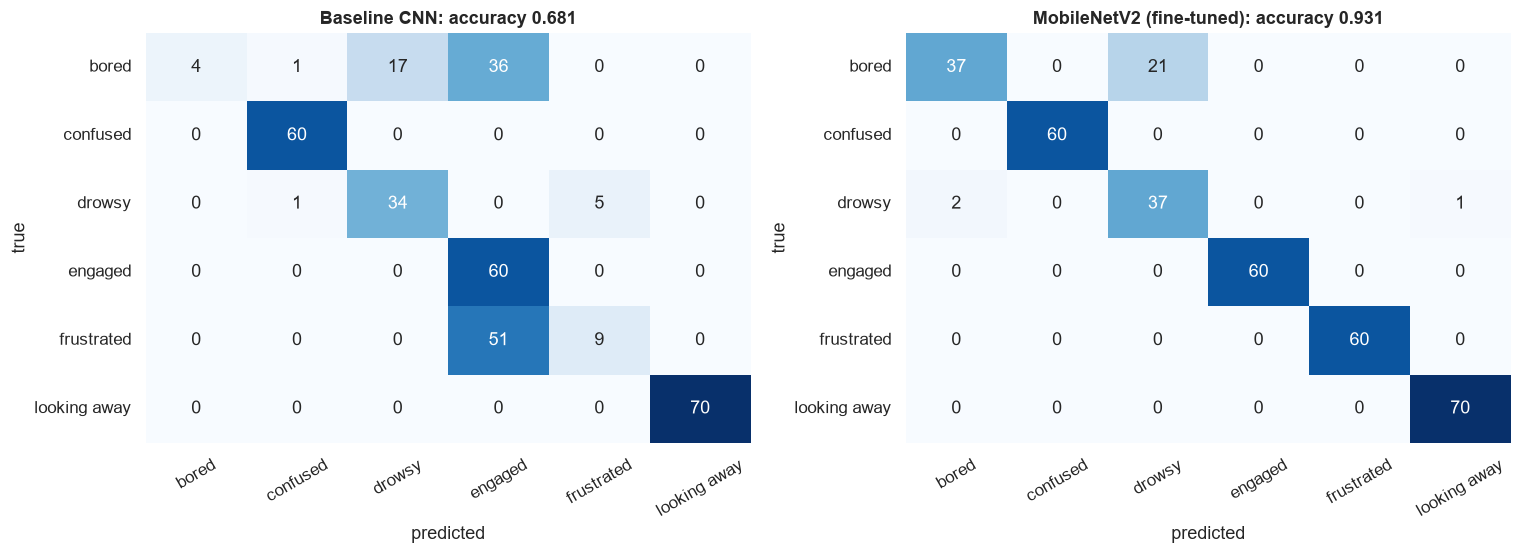

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
labels_nice = [c.replace("_", " ") for c in CLASS_NAMES]
for ax, pred, title in ((axes[0], baseline_pred, "Baseline CNN"), (axes[1], y_pred, "MobileNetV2 (fine-tuned)")):
    cm = confusion_matrix(y_true, pred, labels=list(range(6)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=labels_nice, yticklabels=labels_nice, ax=ax)
    ax.set_title(f"{title}: accuracy {accuracy_score(y_true, pred):.3f}"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_matrices.png", dpi=150); plt.show()

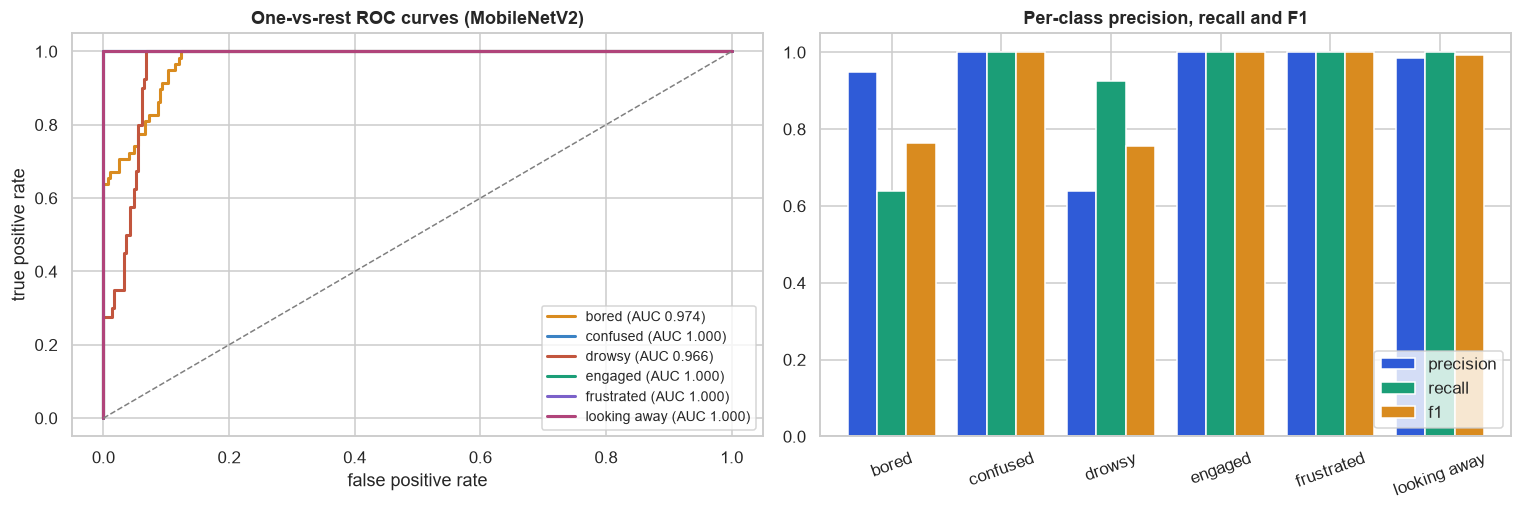

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for i, name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_true == i, proba[:, i])
    axes[0].plot(fpr, tpr, color=COLORS[name], lw=2, label=f"{name.replace('_', ' ')} (AUC {auc(fpr, tpr):.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
axes[0].set_title("One-vs-rest ROC curves (MobileNetV2)"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
axes[0].legend(fontsize=9)

per_class = pd.DataFrame(metrics["per_class"]).T.loc[CLASS_NAMES, ["precision", "recall", "f1"]]
per_class.index = labels_nice
per_class.plot.bar(ax=axes[1], color=["#2f5bd7", "#1b9e77", "#d98b1f"], width=0.8)
axes[1].set_ylim(0, 1.05); axes[1].set_title("Per-class precision, recall and F1"); axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "roc_and_per_class.png", dpi=150); plt.show()

## 9. Error analysis

misclassified: 24 of 348 test images (6.9%)
mean confidence when correct: 0.982
mean confidence when wrong  : 0.829

Most common confusions (true -> predicted):
bored -> drowsy           21
drowsy -> bored            2
drowsy -> looking_away     1

share of errors that cross the engaged / not-engaged boundary: 0%


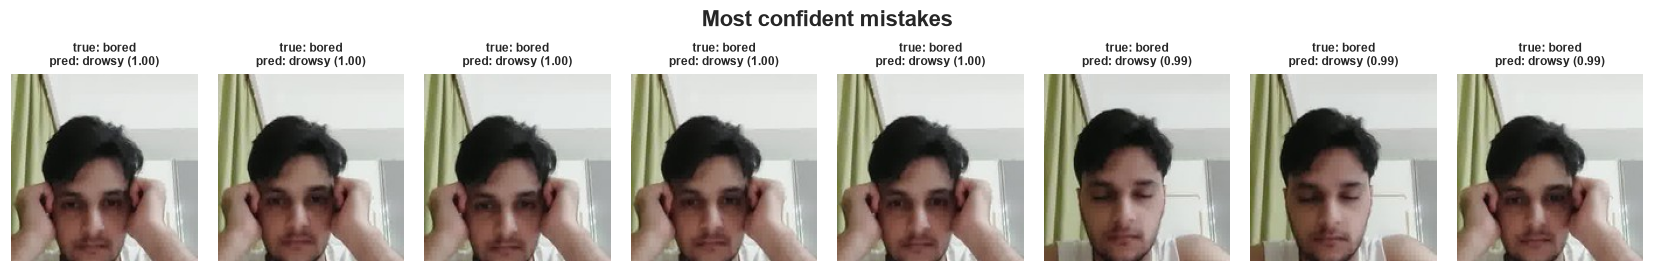

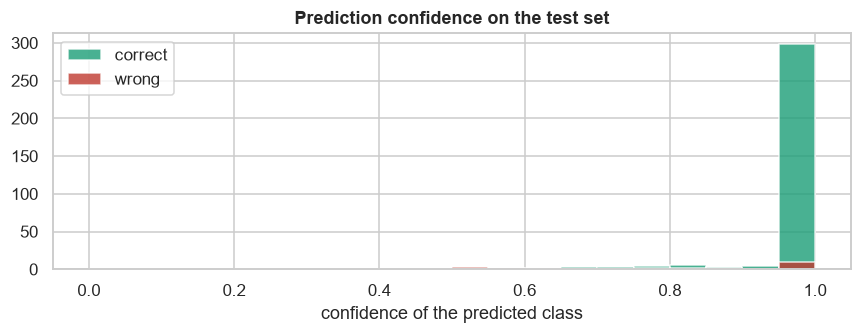

In [23]:
confidence = proba.max(axis=1)
wrong = np.where(y_pred != y_true)[0]
print(f"misclassified: {len(wrong)} of {len(y_true)} test images ({len(wrong) / len(y_true):.1%})")
print(f"mean confidence when correct: {confidence[y_pred == y_true].mean():.3f}")
if len(wrong):
    print(f"mean confidence when wrong  : {confidence[wrong].mean():.3f}")
    pairs = pd.Series([f"{CLASS_NAMES[t]} -> {CLASS_NAMES[p]}" for t, p in zip(y_true[wrong], y_pred[wrong])]).value_counts()
    print("\nMost common confusions (true -> predicted):"); print(pairs.head(6).to_string())
    crossing = np.mean([config.ENGAGEMENT_GROUP[CLASS_NAMES[t]] != config.ENGAGEMENT_GROUP[CLASS_NAMES[p]]
                        for t, p in zip(y_true[wrong], y_pred[wrong])])
    print(f"\nshare of errors that cross the engaged / not-engaged boundary: {crossing:.0%}")

    show = wrong[np.argsort(-confidence[wrong])][:8]
    fig, axes = plt.subplots(1, len(show), figsize=(1.9 * len(show), 2.6), squeeze=False)
    for ax, i in zip(axes[0], show):
        ax.imshow(Image.open(te_p[i])); ax.axis("off")
        ax.set_title(f"true: {CLASS_NAMES[y_true[i]]}\npred: {CLASS_NAMES[y_pred[i]]} ({confidence[i]:.2f})", fontsize=8)
    plt.suptitle("Most confident mistakes", fontweight="bold"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(confidence[y_pred == y_true], bins=20, range=(0, 1), color="#1b9e77", alpha=0.8, label="correct")
if len(wrong):
    ax.hist(confidence[wrong], bins=20, range=(0, 1), color="#c0392f", alpha=0.8, label="wrong")
ax.set_title("Prediction confidence on the test set"); ax.set_xlabel("confidence of the predicted class"); ax.legend()
plt.tight_layout(); plt.show()

## 10. Saving the model

`model_lib.save_model` writes `models/engagement_model.h5` and `models/model_metadata.json` (version number, training date, class order, test metrics). The previous version, if any, is copied to `models/archive/` first. The file is then reloaded and checked against the in-memory model.

In [24]:
if FAST:
    print("FAST dry run: model not saved.")
    reloaded = model
else:
    meta = model_lib.save_model(model, metrics, kind="initial", train_images=len(tr_p), history=history,
                                extra={"hyperparameters": best_params, "validation_images": len(va_p)})
    print(f"saved model v{meta['version']} -> {config.MODEL_PATH.relative_to(config.BASE_DIR)} "
          f"({config.MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
    reloaded = model_lib.load_model()
    check = model_lib.predict_proba(reloaded, te_p[:64])
    print("max difference between in-memory and reloaded predictions:", float(np.abs(check - proba[:64]).max()))

saved model v1 -> models\engagement_model.h5 (9.7 MB)


max difference between in-memory and reloaded predictions: 0.0


## 11. Prediction function

`src/prediction.py` is what the API uses. `predict_image(path)` takes one image file, applies the preprocessing from section 4 and returns the class, its confidence, the engaged / not-engaged group and all six probabilities.

In [25]:
predictor = prediction.Predictor()
if FAST:
    predictor._model, predictor._infer, predictor._mtime = model, (lambda x: model(x, training=False)), 0.0
    predictor.load = lambda force=False: False
else:
    predictor.load()

example = te_p[0]
result = predictor.predict_path(example)
print("file:", Path(example).name, "| true label:", CLASS_NAMES[te_l[0]])
print(json.dumps(result, indent=2))

file: bored_0039.jpg | true label: bored
{
  "label": "bored",
  "confidence": 0.9990702271461487,
  "engagement": "Not engaged",
  "engaged_probability": 0.0006412618677131832,
  "probabilities": {
    "bored": 0.9990702271461487,
    "confused": 0.00017062116239685565,
    "drowsy": 0.0002808049612212926,
    "engaged": 0.00044731743400916457,
    "frustrated": 2.3323273126152344e-05,
    "looking_away": 7.70429596741451e-06
  },
  "inference_ms": 46.44,
  "model_version": 1
}


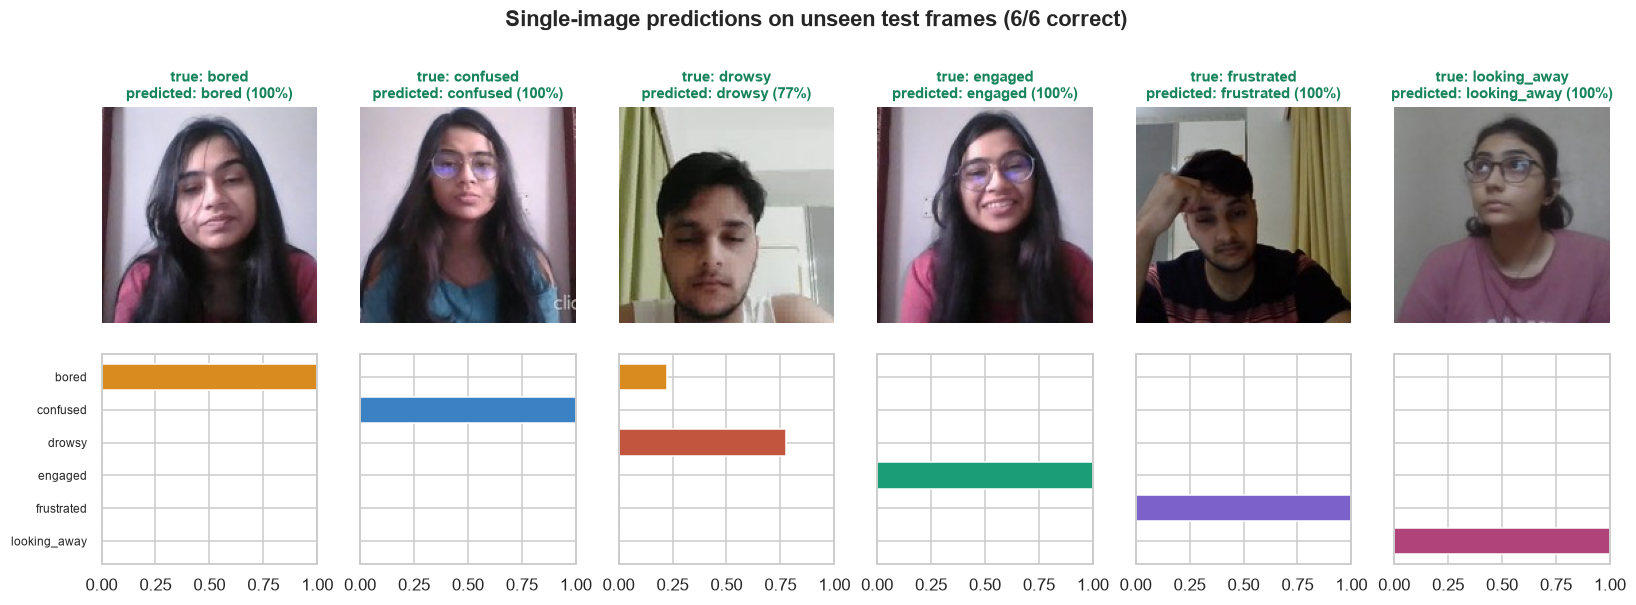

median time for one prediction (preprocessing + inference): 35.5 ms on CPU


In [26]:
# One held-out test image per class: true label vs prediction
fig, axes = plt.subplots(2, 6, figsize=(15, 5.6), gridspec_kw={"height_ratios": [3, 2]})
rng = random.Random(7)
correct = 0
for col, name in enumerate(CLASS_NAMES):
    path = rng.choice(sorted((config.TEST_DIR / name).glob("*.jpg")))
    r = predictor.predict_path(path)
    ok = r["label"] == name; correct += ok
    axes[0, col].imshow(Image.open(path)); axes[0, col].axis("off")
    axes[0, col].set_title(f"true: {name}\npredicted: {r['label']} ({r['confidence']:.0%})",
                           color="#17845b" if ok else "#c0392f", fontsize=10)
    probs = [r["probabilities"][c] for c in CLASS_NAMES]
    axes[1, col].barh(range(6), probs, color=PALETTE); axes[1, col].set_xlim(0, 1); axes[1, col].invert_yaxis()
    axes[1, col].set_yticks(range(6)); axes[1, col].set_yticklabels(CLASS_NAMES if col == 0 else [], fontsize=8)
plt.suptitle(f"Single-image predictions on unseen test frames ({correct}/6 correct)", fontweight="bold")
plt.tight_layout(); plt.show()

times = [predictor.predict_path(example)["inference_ms"] for _ in range(30)]
print(f"median time for one prediction (preprocessing + inference): {np.median(times):.1f} ms on CPU")

## 12. Retraining function

When new labelled images arrive, the model is **not** rebuilt from ImageNet weights. `model_lib.fine_tune_existing` loads the saved model and continues training it, so the current production model acts as the pretrained starting point. In production this is driven by `src/retrain.py`, which:

1. reads the uploaded images from the SQLite database,
2. preprocesses them into `data/train/<label>/` with the functions from section 4,
3. evaluates the live model on the test set,
4. fine-tunes it on the new images plus a replay sample of older training images (so it does not forget them),
5. evaluates the candidate, and
6. promotes it only if test accuracy has not dropped by more than 2 points.

The cell below exercises step 4 on its own, without writing anything to disk. The "new upload" is `data/retrain_pool`: frames that were held back in section 2 and that neither training nor testing has touched.

In [27]:
rng = random.Random(SEED)
# New data: the held-back retrain pool. Replay: 40 training frames per class.
pool_p, pool_l = preprocessing.list_images(config.POOL_DIR)
new_idx = list(range(len(pool_p)))
replay_idx = [i for c in range(6) for i in rng.sample([j for j, l in enumerate(tr_l) if l == c], 40)]
fit_paths = pool_p + [tr_p[i] for i in replay_idx]
fit_labels = pool_l + [tr_l[i] for i in replay_idx]

pool_before = model_lib.evaluate_model(reloaded, pool_p, pool_l)
print(f"saved model on the {len(pool_p)} unseen pool images, before retraining: accuracy {pool_before['accuracy']:.4f}")

before = {"accuracy": metrics["accuracy"], "f1_macro": metrics["f1_macro"], "loss": metrics["loss"]}
candidate, retrain_history = model_lib.fine_tune_existing(
    reloaded, fit_paths, fit_labels, [], [], epochs=1 if FAST else 2, learning_rate=5e-5, verbose=2)
after = model_lib.evaluate_model(candidate, te_p, te_l)

print(f"\nfine-tuned the saved model on {len(fit_paths)} images ({len(new_idx)} new + {len(replay_idx)} replay)")
pd.DataFrame({"before retraining": before, "after retraining": {k: after[k] for k in before}}).round(4)

saved model on the 170 unseen pool images, before retraining: accuracy 0.9412
Epoch 1/2


13/13 - 12s - 902ms/step - accuracy: 0.9610 - loss: 0.0931


Epoch 2/2


13/13 - 6s - 453ms/step - accuracy: 0.9707 - loss: 0.0994



fine-tuned the saved model on 410 images (170 new + 240 replay)


,before retraining,after retraining
accuracy,0.9310,0.9253
f1_macro,0.9185,0.9140
loss,0.2218,0.2353


**Result.** The saved model already scores 0.941 on the 170 pool images it has never seen. Two fine-tuning epochs at learning rate 5e-5 moved test accuracy from 0.9310 to 0.9253, a difference of two test images. Retraining on more data from the same sessions does not add new information, so no gain is expected here; the point of this cell is that the mechanism works and that the saved model is the starting point.

Repeating this with several settings showed where the movement comes from: at 5e-5 the `bored` / `drowsy` boundary shifts from epoch to epoch and test accuracy swings between 0.88 and 0.93, while at 1e-5 it stays between 0.917 and 0.931. Production retraining therefore defaults to **1e-5** (`config.RETRAIN_LR`) with early stopping on validation loss, and step 6 above (promote only if test accuracy holds within 2 points) guards against a bad run replacing a good model.

The retrained candidate is only a demonstration and is discarded; the file in `models/` is still the model saved in section 10. In the deployed system the same function runs when the **Start retraining** button is pressed or when an automatic trigger fires (200 new images waiting, or the mean confidence of recent predictions dropping below 60% with new labelled data available).

## 13. Conclusions and limitations

In [28]:
summary = {
    "Test accuracy": metrics["accuracy"], "Test loss": metrics["loss"], "Precision (macro)": metrics["precision_macro"],
    "Recall (macro)": metrics["recall_macro"], "F1 (macro)": metrics["f1_macro"], "ROC-AUC (OvR)": metrics["roc_auc_ovr"],
    "Engaged vs not engaged accuracy": metrics["engaged_vs_not_accuracy"],
    "Baseline CNN accuracy": accuracy_score(y_true, baseline_pred),
}
pd.Series(summary).round(4).to_frame("value")

,value
Test accuracy,0.9310
Test loss,0.2218
Precision (macro),0.9288
Recall (macro),0.9272
F1 (macro),0.9185
ROC-AUC (OvR),0.9901
Engaged vs not engaged accuracy,1.0000
Baseline CNN accuracy,0.6810


### What worked

* **Transfer learning beats training from scratch by a wide margin.** The fine-tuned MobileNetV2 reaches **93.1% accuracy, 0.919 macro F1 and 0.990 ROC-AUC** on 348 held-out frames. The baseline CNN trained from scratch on the same data reaches 68.1% accuracy and 0.614 macro F1.
* **Four of the six classes are classified without a single miss** (`confused`, `engaged`, `frustrated` and `looking_away` all have recall 1.00).
* **Fine-tuning the backbone was the decisive step.** With a frozen backbone, validation accuracy stalled near 0.70 because `engaged` and `frustrated` could not be separated under augmentation. Unfreezing the top 30 layers took it to 0.99.
* **Prediction is fast enough for CPU serving:** about 35 ms per image including preprocessing.

### What the errors say

All 24 test errors stay inside the *not engaged* group, and 21 of them are `bored` frames predicted as `drowsy`. Both classes contain the same student in the same room, with lowered eyes or a dropped head in both, so the line between them is partly a labelling judgement. For the question a teacher actually asks, "is this student with me or not?", the model makes **no errors on this test set** (engaged vs not engaged accuracy 1.00). `bored` recall (0.64) is the number to improve if the six-way distinction matters.

### Limitations

* **Same sessions in train and test.** The dataset has a handful of students and rooms and no student identifiers, so a split by student was not possible. The block-wise split removes near-duplicate neighbouring frames, but the reported scores are accuracy on new frames from known sessions. Section 3 showed that image statistics unrelated to expression separate some classes, so part of the score is the model recognising the room. Accuracy on a new student or webcam will be lower.
* **Acted labels.** The states were posed for the camera. Real boredom and confusion are subtler and mixed.
* **Single frames.** Engagement is behaviour over time. A deployed system should aggregate predictions over a window of frames before raising any flag.
* **Sensitive data.** Faces of students are personal data. Real use needs informed consent and should support a tutor's judgement, not replace it.

### Next steps

1. Collect frames from many more students and evaluate with a **split by student**.
2. Crop to the detected face before classification, to remove the background shortcut.
3. Smooth predictions over time (for example a majority vote over 10 seconds).
4. Keep the model current through the retraining loop in `src/retrain.py`: every batch of new labelled images from new students is exactly the data this model is missing.
